# Predictive Industrial Maintenance Using Machine Learning




In [5]:
%pip install pandas numpy matplotlib scikit-learn pgmpy

In [6]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_absolute_error, mean_squared_error
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.neural_network import MLPClassifier, MLPRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Imports ready.")

Imports ready.


In [7]:
df = pd.read_csv("ai4i2020.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Columns:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,missing values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Target distribution:


,count
Machine failure,
0,9661
1,339


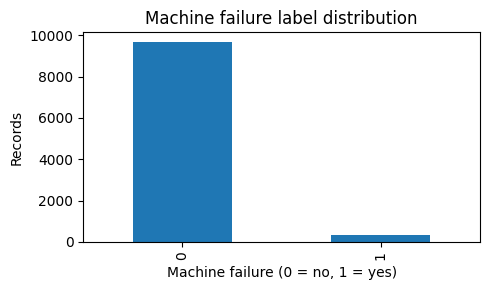

In [8]:
# Normalize common column-name variants if needed
df.columns = [c.strip() for c in df.columns]

target_col = "Machine failure"
if target_col not in df.columns:
    raise ValueError(f"Could not find '{target_col}'. Available columns: {df.columns.tolist()}")

display(df.isna().sum().to_frame("missing values"))
print("\nTarget distribution:")
display(df[target_col].value_counts(dropna=False).to_frame("count"))

plt.figure(figsize=(5, 3))
df[target_col].value_counts().sort_index().plot(kind="bar")
plt.title("Machine failure label distribution")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

In [9]:
# Remove identifiers and target-leakage columns from features
exclude_cols = {
    target_col, "UDI", "Product ID",
    "TWF", "HDF", "PWF", "OSF", "RNF"
}
feature_cols = [c for c in df.columns if c not in exclude_cols]

X_raw = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

# Encode categorical columns, e.g. machine Type (L/M/H)
X = pd.get_dummies(X_raw, drop_first=False, dtype=float)

print("Feature matrix shape:", X.shape)
display(X.head())

Feature matrix shape: (10000, 8)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0.0,0.0,1.0
1,298.2,308.7,1408,46.3,3,0.0,1.0,0.0
2,298.1,308.5,1498,49.4,5,0.0,1.0,0.0
3,298.2,308.6,1433,39.5,7,0.0,1.0,0.0
4,298.2,308.7,1408,40.0,9,0.0,1.0,0.0


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# For the course's traditional ML models, we use a pipeline so scaling is fit on training folds only.
scaled_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_scaled = scaled_preprocessor.fit_transform(X_train)
X_test_scaled = scaled_preprocessor.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (8000, 8)  Test: (2000, 8)


              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



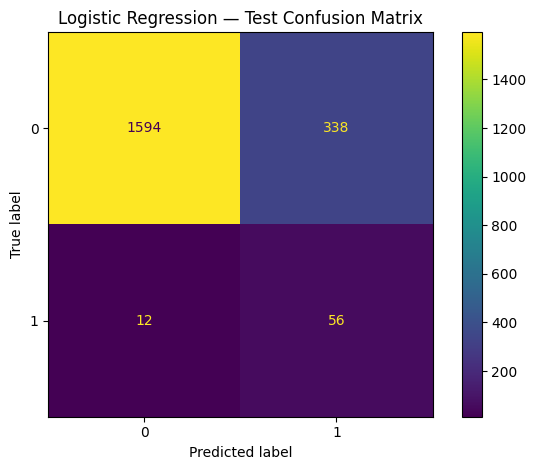

In [11]:
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
log_pred = log_reg.predict(X_test_scaled)

print(classification_report(y_test, log_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, log_pred)
plt.title("Logistic Regression — Test Confusion Matrix")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.68      0.25      0.37        68

    accuracy                           0.97      2000
   macro avg       0.83      0.62      0.68      2000
weighted avg       0.96      0.97      0.96      2000



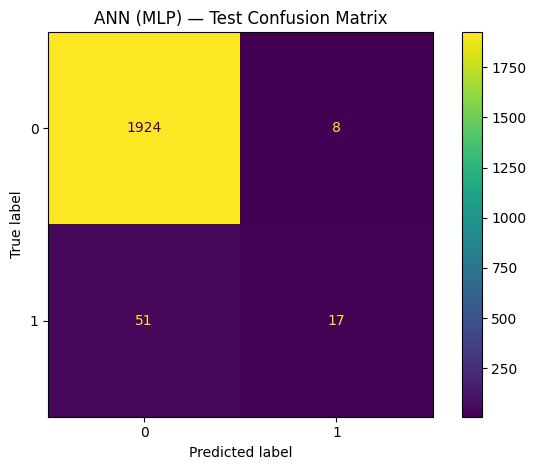

In [12]:
ann = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=250,
    early_stopping=True,
    random_state=RANDOM_STATE
)
ann.fit(X_train_scaled, y_train)
ann_pred = ann.predict(X_test_scaled)

print(classification_report(y_test, ann_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, ann_pred)
plt.title("ANN (MLP) — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Decision Tree (entropy)": DecisionTreeClassifier(
        criterion="entropy", class_weight="balanced", random_state=RANDOM_STATE
    ),
    "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    fitted_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

model_results = pd.DataFrame(results).sort_values("F1", ascending=False)
display(model_results)

,Model,Accuracy,Precision,Recall,F1
2,Decision Tree (entropy),0.9795,0.701493,0.691176,0.696296
0,KNN,0.9740,0.833333,0.294118,0.434783
3,SVM (RBF),0.9170,0.279279,0.911765,0.427586
1,Naive Bayes,0.9580,0.250000,0.117647,0.160000


In [14]:
tree = DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE)

# sklearn versions differ on the base-estimator argument name
try:
    bagging = BaggingClassifier(estimator=tree, n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
except TypeError:
    bagging = BaggingClassifier(base_estimator=tree, n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

boosting = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)
random_forest = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)

ensemble_models = {
    "Bagging": bagging,
    "AdaBoost": boosting,
    "Random Forest": random_forest
}

ensemble_results = []
for name, model in ensemble_models.items():
    model.fit(X_train, y_train)  # Tree-based models do not require scaling
    pred = model.predict(X_test)
    ensemble_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

ensemble_results = pd.DataFrame(ensemble_results).sort_values("F1", ascending=False)
display(ensemble_results)

,Model,Accuracy,Precision,Recall,F1
0,Bagging,0.974,0.590909,0.764706,0.666667
2,Random Forest,0.979,0.906250,0.426471,0.580000
1,AdaBoost,0.970,0.722222,0.191176,0.302326


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
])

cv_f1 = cross_val_score(cv_pipeline, X, y, cv=cv, scoring="f1")
print("5-fold F1 scores:", np.round(cv_f1, 4))
print("Mean F1:", round(cv_f1.mean(), 4), "+/-", round(cv_f1.std(), 4))

5-fold F1 scores: [0.2278 0.2318 0.2281 0.2324 0.2409]
Mean F1: 0.2322 +/- 0.0047


In [16]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
continuous_target = "Torque [Nm]" if "Torque [Nm]" in numeric_cols else None

if continuous_target is not None:
    reg_features = [c for c in numeric_cols if c not in {
        continuous_target, target_col, "UDI", "TWF", "HDF", "PWF", "OSF", "RNF"
    }]
    Xr = df[reg_features].copy()
    yr = df[continuous_target].copy()
    Xr_train, Xr_test, yr_train, yr_test = train_test_split(
        Xr, yr, test_size=0.2, random_state=RANDOM_STATE
    )
    reg_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LinearRegression())
    ])
    reg_pipe.fit(Xr_train, yr_train)
    yr_pred = reg_pipe.predict(Xr_test)
    print("Linear regression target:", continuous_target)
    print("MAE:", round(mean_absolute_error(yr_test, yr_pred), 4))
    print("RMSE:", round(np.sqrt(mean_squared_error(yr_test, yr_pred)), 4))
else:
    print("No suitable continuous target found; select a continuous sensor column manually.")

Linear regression target: Torque [Nm]
MAE: 3.6862
RMSE: 4.8979


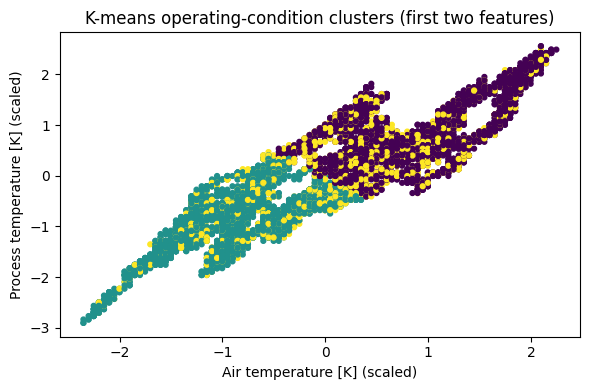

Machine failure         0         1
Cluster                            
0                0.947583  0.052417
1                0.978342  0.021658
2                0.977594  0.022406


In [17]:
cluster_cols = [c for c in [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
] if c in df.columns]

if len(cluster_cols) >= 2:
    cluster_data = df[cluster_cols].replace([np.inf, -np.inf], np.nan)
    cluster_data = SimpleImputer(strategy="median").fit_transform(cluster_data)
    cluster_scaled = StandardScaler().fit_transform(cluster_data)

    kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
    clusters = kmeans.fit_predict(cluster_scaled)

    plt.figure(figsize=(6, 4))
    plt.scatter(cluster_scaled[:, 0], cluster_scaled[:, 1], c=clusters, s=12)
    plt.xlabel(cluster_cols[0] + " (scaled)")
    plt.ylabel(cluster_cols[1] + " (scaled)")
    plt.title("K-means operating-condition clusters (first two features)")
    plt.tight_layout()
    plt.show()

    print(pd.crosstab(pd.Series(clusters, name="Cluster"), y.reset_index(drop=True), normalize="index"))
else:
    print("Expected sensor columns were not found.")

In [18]:
if len(cluster_cols) >= 2:
    gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=RANDOM_STATE)
    gmm_labels = gmm.fit_predict(cluster_scaled)
    print("GMM cluster counts:")
    print(pd.Series(gmm_labels).value_counts().sort_index())
    print("\nAverage model log-likelihood:", round(gmm.score(cluster_scaled), 4))

GMM cluster counts:
0    1503
1    4627
2    3870
Name: count, dtype: int64

Average model log-likelihood: -5.2006


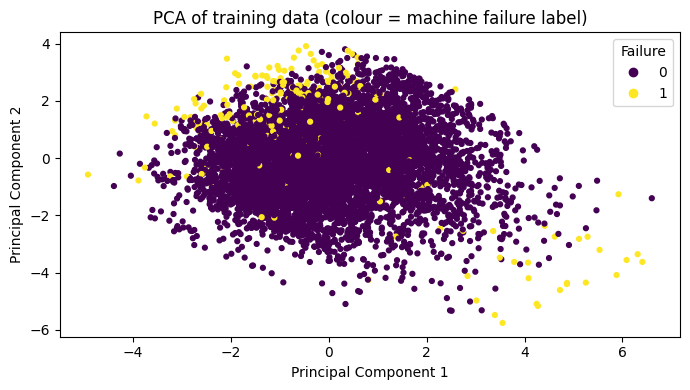

Explained variance ratio: [0.2389 0.2308]
Total variance explained by 2 components: 0.4697


In [19]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(7, 4))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, s=12)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of training data (colour = machine failure label)")
plt.legend(*scatter.legend_elements(), title="Failure")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance explained by 2 components:", round(pca.explained_variance_ratio_.sum(), 4))

In [21]:
 %pip install pgmpy

In [23]:

    from pgmpy.models import DiscreteBayesianNetwork
    from pgmpy.factors.discrete import TabularCPD
    from pgmpy.inference import VariableElimination

    # Illustrative dependency structure:
    # HighTemperature -> FailureRisk <- HighTorque
    bn = DiscreteBayesianNetwork([
        ("HighTemperature", "FailureRisk"),
        ("HighTorque", "FailureRisk")
    ])

    cpd_temp = TabularCPD("HighTemperature", 2, [[0.8], [0.2]])
    cpd_torque = TabularCPD("HighTorque", 2, [[0.7], [0.3]])

    # Evidence state order: (HighTemperature, HighTorque)
    # Each column gives P(FailureRisk=0) and P(FailureRisk=1)
    cpd_risk = TabularCPD(
        "FailureRisk", 2,
        values=[
            [0.99, 0.90, 0.85, 0.60],
            [0.01, 0.10, 0.15, 0.40]
        ],
        evidence=["HighTemperature", "HighTorque"],
        evidence_card=[2, 2]
    )

    bn.add_cpds(cpd_temp, cpd_torque, cpd_risk)
    print("Bayesian network valid:", bn.check_model())
    inference = VariableElimination(bn)
    print(inference.query(variables=["FailureRisk"], evidence={"HighTemperature": 1}))


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Bayesian network valid: True
+----------------+--------------------+
| FailureRisk    |   phi(FailureRisk) |
+================+====================+
| FailureRisk(0) |             0.7750 |
+----------------+--------------------+
| FailureRisk(1) |             0.2250 |
+----------------+--------------------+


In [24]:
# Each example: (Temperature, Vibration, ToolWear), target = "MaintenanceNeeded"?
examples = [
    (("High", "High", "High"), "Yes"),
    (("High", "High", "Low"), "Yes"),
    (("Low", "Low", "Low"), "No"),
    (("High", "Low", "Low"), "No"),
]
domains = [
    ["Low", "High"],
    ["Low", "High"],
    ["Low", "High"]
]

def covers(hypothesis, x):
    return all(h == "?" or h == value for h, value in zip(hypothesis, x))

def minimally_generalize(h, x):
    return tuple(value if old == "Ø" else old if old == value or old == "?" else "?"
                 for old, value in zip(h, x))

# Simplified version-space boundary illustration:
S = [("Ø", "Ø", "Ø")]
G = [("?", "?", "?")]

for x, label in examples:
    if label == "Yes":
        S = [minimally_generalize(h, x) for h in S]
        G = [g for g in G if covers(g, x)]
    else:
        G = [g for g in G if not covers(g, x)]
        S = [s for s in S if not covers(s, x)]

print("Illustrative specific boundary S:", S)
print("Illustrative general boundary G:", G)
print("Note: this compact demonstration is intended to show the concept; full boundary pruning is required for a rigorous Candidate Elimination implementation.")

Illustrative specific boundary S: [('High', 'High', '?')]
Illustrative general boundary G: []
Note: this compact demonstration is intended to show the concept; full boundary pruning is required for a rigorous Candidate Elimination implementation.


,Model,Accuracy,Precision,Recall,F1
0,Decision Tree (entropy),0.9795,0.701493,0.691176,0.696296
4,Bagging,0.9740,0.590909,0.764706,0.666667
5,Random Forest,0.9790,0.906250,0.426471,0.580000
1,KNN,0.9740,0.833333,0.294118,0.434783
2,SVM (RBF),0.9170,0.279279,0.911765,0.427586
6,AdaBoost,0.9700,0.722222,0.191176,0.302326
3,Naive Bayes,0.9580,0.250000,0.117647,0.160000


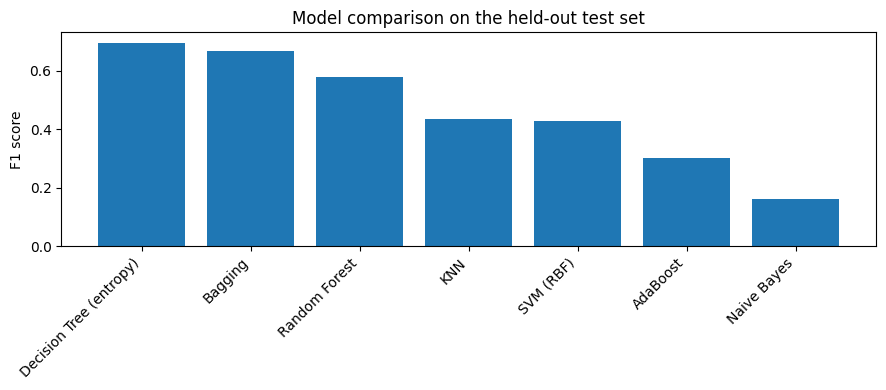

In [25]:
all_comparison = pd.concat([
    model_results,
    ensemble_results
], ignore_index=True).sort_values("F1", ascending=False)

display(all_comparison)

plt.figure(figsize=(9, 4))
plt.bar(all_comparison["Model"], all_comparison["F1"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("F1 score")
plt.title("Model comparison on the held-out test set")
plt.tight_layout()
plt.show()

In [28]:
def predict_machine_failure(input_record):

    row = pd.DataFrame([input_record])

    row = pd.get_dummies(row, drop_first=False, dtype=float)

    row = row.reindex(columns=X.columns, fill_value=0)

    row_scaled = scaled_preprocessor.transform(row)

    pred = int(ann.predict(row_scaled)[0])
    probability = float(ann.predict_proba(row_scaled)[0, 1])

    return {
        "predicted_failure": pred,
        "failure_probability": round(probability * 100, 2),
        "interpretation": (
            "Possible machine failure detected"
            if pred == 1
            else "No machine failure predicted"
        )
    }


# Example usage
sample_machine = {
    "Type": "M",
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 45.0,
    "Tool wear [min]": 200
}

result = predict_machine_failure(sample_machine)

print("Prediction:", result["interpretation"])
print("Failure probability:", f'{result["failure_probability"]}%')
print("Predicted class:", result["predicted_failure"])

Prediction: No machine failure predicted
Failure probability: 1.23%
Predicted class: 0


In [33]:
!pip install pyngrok